# Step 3: Garden's margin depends on one costing assumption

**Decision.** Garden's reported gross margin is 47%, against 65% at Harbour and 63% at Uptown. Should Stories treat Garden as an underperforming branch, by cutting its menu, raising its prices or changing its management?

**Short answer.**
- **Measured:** across all 45 products, Garden's recorded unit costs are about 43% higher than Harbour's. Every one equals Harbour's cost ÷ 0.7, within one cent of rounding. The pattern holds even for sealed bottled water, and recorded costs never change during the six months.
- **Explains the gap:** the reported margin gap is **largely explained by these recorded unit costs**. It does not show that the branch is badly managed.
- **Centrepiece:** if Garden's actual quantities, prices and discounts are kept and only its unit costs are replaced with Harbour's, six-month gross profit rises by **$15,923** and Garden's margin goes from **46.9% to 62.9%**, in line with the other branches.
- **Interpretation:** the near-uniform multiplier suggests a **systematic costing or pricing rule that should be audited**. Possible explanations include supplier pricing, allocated overhead, internal transfer pricing or a configuration error. This dataset cannot tell which.
- **Recommendation:** audit Garden's costing before acting on its margin. Compare invoices *and* the recorded costing rules for water and a few representative products at Garden and Harbour.

**Money at stake (estimates, not confirmed savings).** About $32,100 a year (the 181 observed days scaled to 365). As a scenario at June's sales rate: about $38,700. It is recoverable cash only if Garden really pays more for the same goods.

The 10% discount is covered briefly in Section 8, because it is a much smaller problem.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(ROOT / "data" / "raw" / "stories_transactions.csv")
raw["Date"] = pd.to_datetime(raw["Date"])
DAYS = raw["Date"].nunique()

cost_range = raw.groupby(["Product", "Branch"])["Unit Cost (USD)"].agg(["min", "max"])
price_range = raw.groupby(["Product", "Branch"])["Unit Price (USD)"].agg(["min", "max"])
print("Product-branch pairs whose unit cost ever changes in 6 months:", int((cost_range["min"] != cost_range["max"]).sum()), "of", len(cost_range))
print("Product-branch pairs whose list price ever changes:", int((price_range["min"] != price_range["max"]).sum()), "of", len(price_range))
C = cost_range["min"].unstack()
PR = price_range["min"].unstack()

Product-branch pairs whose unit cost ever changes in 6 months: 0 of 135
Product-branch pairs whose list price ever changes: 0 of 135


## 1. Observed facts: the cost pattern

**Observed:** no unit cost or list price changes from January to June. Real purchase costs usually move with supplier invoices, exchange rates and seasons. This suggests the "Unit Cost" field holds **standard costs from a cost table** rather than costs measured from what was actually spent. That affects how every margin in this dataset should be read.

In [2]:
ratio = C["Garden"] / C["Harbour"]
rule = (C["Harbour"] / 0.7).round(2)
print(f"Garden / Harbour cost: mean {ratio.mean():.4f}, sd {ratio.std():.4f}, range {ratio.min():.4f}-{ratio.max():.4f}")
print(f"Garden cost within 1 cent of Harbour cost / 0.7: {int(((rule - C['Garden']).abs() <= 0.0101).sum())} of {len(C)} products")
print(f"Uptown / Harbour cost: range {(C['Uptown']/C['Harbour']).min():.3f}-{(C['Uptown']/C['Harbour']).max():.3f}")
print(f"Garden / Harbour list price: mean {(PR['Garden']/PR['Harbour']).mean():.4f} (about 1/1.05)")
print("\nSealed items, which need no preparation:")
display(pd.concat({"unit cost": C, "list price": PR}, axis=1).loc[["Still Water", "Sparkling Water"]])

Garden / Harbour cost: mean 1.4301, sd 0.0019, range 1.4261-1.4386
Garden cost within 1 cent of Harbour cost / 0.7: 45 of 45 products
Uptown / Harbour cost: range 0.952-0.965
Garden / Harbour list price: mean 0.9524 (about 1/1.05)

Sealed items, which need no preparation:


unit cost                list price               
Branch             Garden Harbour Uptown     Garden Harbour Uptown
Product                                                           
Still Water          0.93    0.65   0.62       1.95    2.05   1.87
Sparkling Water      1.93    1.35   1.30       2.75    2.89   2.64

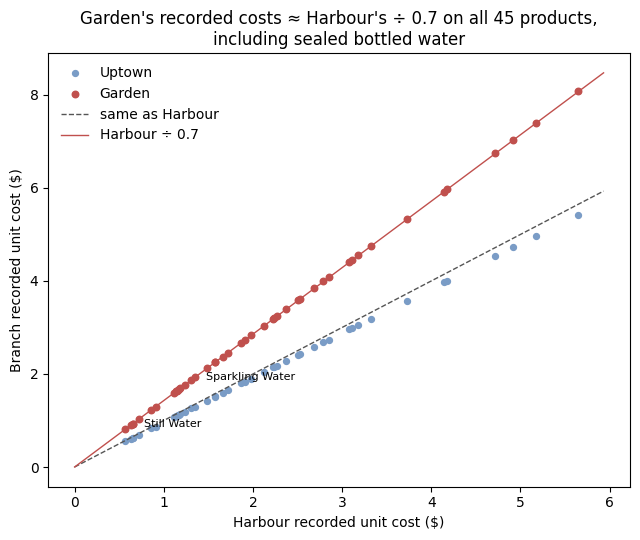

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(C["Harbour"], C["Uptown"], s=18, color="#7a9cc6", label="Uptown")
ax.scatter(C["Harbour"], C["Garden"], s=22, color="#c0504d", label="Garden")
x = np.linspace(0, C["Harbour"].max() * 1.05, 50)
ax.plot(x, x, color="#555", lw=1, ls="--", label="same as Harbour")
ax.plot(x, x / 0.7, color="#c0504d", lw=1, label="Harbour ÷ 0.7")
for item in ["Still Water", "Sparkling Water"]:
    ax.annotate(item, (C.loc[item, "Harbour"], C.loc[item, "Garden"]), xytext=(8, -2), textcoords="offset points", fontsize=8)
ax.set_xlabel("Harbour recorded unit cost ($)"); ax.set_ylabel("Branch recorded unit cost ($)")
ax.set_title("Garden's recorded costs ≈ Harbour's ÷ 0.7 on all 45 products,\nincluding sealed bottled water")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "garden_cost_rule.png", dpi=150); plt.show()

## 2. Centrepiece: how much of the margin gap do recorded costs explain?

We keep everything Garden actually sold (quantities, prices, discounts) and change **only** the unit costs. If Garden's margin gap disappeared under another branch's costs, the gap would come from costs, not sales. Every row below is a scenario, not a measured outcome.

In [4]:
g = raw[raw.Branch == "Garden"].copy()
rev_g = g["Line Revenue (USD)"].sum()
gp_rec = g["Line Gross Profit (USD)"].sum()
scen = {
    "Recorded costs (as reported)": g.Quantity * g["Unit Cost (USD)"],
    "Half of the gap is real": g.Quantity * (g["Unit Cost (USD)"] + g.Product.map(C["Harbour"])) / 2,
    "Harbour's unit costs": g.Quantity * g.Product.map(C["Harbour"]),
    "Uptown's unit costs": g.Quantity * g.Product.map(C["Uptown"]),
}
rows = []
for name, cost in scen.items():
    gp = rev_g - cost.sum()
    rows.append({"scenario": name, "Garden gross profit $": gp, "margin %": gp / rev_g * 100, "change vs reported $": gp - gp_rec})
norm = pd.DataFrame(rows).set_index("scenario")
display(norm.round(1))

b = raw.groupby("Branch").agg(revenue=("Line Revenue (USD)", "sum"), gross_profit=("Line Gross Profit (USD)", "sum"),
                              purchases=("Transaction ID", "nunique"), units=("Quantity", "sum"))
b["margin %"] = b.gross_profit / b.revenue * 100
display(b.round(1))

,Garden gross profit $,margin %,change vs reported $
scenario,,,
Recorded costs (as reported),46794.5,46.9,0.0
Half of the gap is real,54756.2,54.9,7961.7
Harbour's unit costs,62718.0,62.9,15923.5
Uptown's unit costs,64204.3,64.4,17409.8


,revenue,gross_profit,purchases,units,margin %
Branch,,,,,
Garden,99748.6,46794.5,11163,17833,46.9
Harbour,150483.6,97753.9,16334,26093,65.0
Uptown,55693.0,34882.1,6390,10161,62.6


**Result.** With Harbour's unit costs, Garden's margin is 62.9%, close to Uptown's 62.6% and a little below Harbour's 65.0%. **The reported gap is almost entirely a cost-table difference.** Whether Garden looks like the weakest branch or an average one depends on a single costing assumption the data cannot verify. A CEO who acts on the reported 47% is acting on that assumption.

## 3. Possible explanations, and what the data can and cannot say

| Explanation | What it would usually leave in the data | What the data shows | Assessment |
|---|---|---|---|
| Kitchen waste, spoilage, theft, portions measured product by product | Gaps that differ by product (fresh food worse than sealed bottles) and drift over time | Near-identical ×1.43 on every product, including sealed water; no change over time | **Unlikely to be measured directly in these costs.** But waste *could* be spread evenly into standard costs, so it cannot be fully excluded |
| Smaller branch gets worse volume terms | Smallest branch pays the most | Uptown is smallest (10,161 units) and has the *lowest* recorded costs | **Not supported** |
| Different product mix | A gap that disappears product-by-product | The gap holds within every product | **Not supported** |
| Supplier or delivery pricing specific to Garden | One multiplier, fixed for the period | Consistent | Possible |
| Allocated overhead (e.g. rent) loaded into unit costs | One round multiplier on every item | Consistent | Possible |
| Internal transfer pricing (e.g. a central kitchen charging Garden more) | One multiplier on every item | Consistent | Possible |
| Configuration or data-entry error in the cost table | One round multiplier (÷ 0.7), never updated | Consistent | Possible |

**What we can claim:** the pattern is systematic and uniform, the kind a costing or pricing *rule* produces. **What we cannot claim:** which rule it is, or whether Garden's real economics are worse. Settling that needs records outside this dataset (Section 6).

In [5]:
mix = raw.groupby(["Branch", "Category"])["Quantity"].sum()
mix = (mix / mix.groupby(level=0).transform("sum") * 100).unstack(0).round(1)
mix

Branch,Garden,Harbour,Uptown
Category,,,
Bakery,20.9,22.4,20.7
Breakfast,4.7,4.5,4.6
Cold Coffee,13.8,14.9,13.8
Cold Drinks,10.1,10.1,10.4
Desserts,11.0,7.8,7.0
Hot Coffee,15.5,16.2,15.8
Matcha & Tea,14.6,15.0,14.6
Meals,2.8,2.7,2.9
Sandwiches,6.6,6.5,10.2


**Observed:** the product mix is broadly similar across branches. Garden sells somewhat more desserts and Uptown more sandwiches. Since the cost gap holds *within* each product, mix does not explain it.

## 4. Money at stake — measured versus scenario

In [6]:
g["gap"] = g.Quantity * (g["Unit Cost (USD)"] - g.Product.map(C["Harbour"]))
gap = g.gap.sum()
monthly = g.groupby(g.Date.dt.month).gap.sum()
print(f"Gap at recorded costs, {DAYS} observed days (measured from the cost field): ${gap:,.0f}")
print(f"Annualised over the observed period ({DAYS} days -> 365): ${gap * 365 / DAYS:,.0f}")
print("Gap by month:", {m: round(v) for m, v in monthly.items()})
print(f"Scenario: June's monthly gap x 12 (if June's higher volume persists): ${monthly.iloc[-1] * 12:,.0f}")

Gap at recorded costs, 181 observed days (measured from the cost field): $15,923
Annualised over the observed period (181 days -> 365): $32,111
Gap by month: {1: 2154, 2: 2214, 3: 2654, 4: 2713, 5: 2965, 6: 3224}
Scenario: June's monthly gap x 12 (if June's higher volume persists): $38,686


**Measured:** a $15,923 difference in *recorded* cost over 181 days. It grows each month with Garden's sales ($2,154 in January, $3,224 in June). **Estimated:** about $32,100 a year at the observed average, or about $38,700 in a scenario where June's volume persists.

Neither figure is a confirmed saving. They are recoverable cash **only** if Garden really pays more for the same goods. If the rule is an overhead allocation, transfer price or error, the cash saving is zero, but the *decision* value is still large: Stories would avoid penalising a branch whose real margin may be normal.

## 5. Why raising Garden's prices is not the first fix

In [7]:
to_harbour_prices = (g.Quantity * g.Product.map(PR["Harbour"]) * (1 - g["Discount Rate"])).sum() - rev_g
print(f"Matching Harbour's prices, if volume held: +${to_harbour_prices:,.0f} — only {to_harbour_prices/gap:.0%} of the recorded gap")
print(f"Price rise needed to close the whole recorded gap at the same volume: +{gap/rev_g:.0%}")

Matching Harbour's prices, if volume held: +$4,985 — only 31% of the recorded gap
Price rise needed to close the whole recorded gap at the same volume: +16%


Garden is priced at about Harbour ÷ 1.05. Closing the recorded gap through prices would need about **+16%**. Because prices never change in the data, it cannot show how customers would react, and many customers can easily use another branch. If the gap reflects a costing rule rather than real costs, a price rise would charge customers to fix a number. **We reject price changes as the first response.**

## 6. Decisions that depend on the audit, and the practical check

| If the audit finds… | Garden's economic margin | Action | Value |
|---|---|---|---|
| Garden's suppliers really charge ~43% more | ≈ 47% (as reported) | Renegotiate, or move Garden to Harbour's/Uptown's supply terms | Up to ≈ $32k/yr (scenario: ≈ $39k), minus any extra delivery cost |
| Overhead allocation or internal transfer price | Depends on the policy | Report Garden's margin before and after allocations, so branch performance and overhead are judged separately | Better decisions about the 2nd-largest branch |
| A configuration or entry error | ≈ 63% | Correct the cost table; restate Garden's margin | Avoids penalising a normal branch |

**The check (a first step, not necessarily the whole answer):**
1. For **still water, sparkling water and 3–4 representative products** (one coffee, one bakery item, one sandwich), compare Garden's and Harbour's **supplier invoices** for the same month.
2. Ask finance **how the Unit Cost field is filled in** per branch: invoice price, standard cost, transfer price, or a cost with allocations added.
3. **Decision rule:** if invoice prices differ by about 40%, it is a supply issue; if they match, the difference is in the costing rule. Fix accordingly before any margin-based decision about Garden.

In [8]:
m = ((PR - C) / PR * 100).round(1)
print("Products with recorded margin of 35% or less — Garden:", int((m["Garden"] <= 35).sum()), "| Harbour:", int((m["Harbour"] <= 35).sum()))
pd.DataFrame({"Garden margin %": m["Garden"], "Harbour margin %": m["Harbour"]}).sort_values("Garden margin %").head(8)

Products with recorded margin of 35% or less — Garden: 5 | Harbour: 0


,Garden margin %,Harbour margin %
Product,,
Sparkling Water,29.8,53.3
Turkey & Cheese Sandwich,30.1,53.4
Chicken Pesto Sandwich,31.3,54.2
Brownie,34.2,56.2
Cheesecake Slice,34.8,56.6
Chicken Salad Bowl,35.1,56.8
Avocado Toast,36.7,57.9
Frozen Yoghurt Cup,37.4,58.4


**Why this matters for everyday decisions:** at recorded costs, five Garden products have margins of 35% or less, against none at Harbour. A product-range review based on those numbers would cut or reprice items at Garden that look identical to healthy products elsewhere. The same applies to the gross-profit figures in Step 2. Step 2 tests how its conclusion changes under other cost assumptions and finds it does not change.

## 7. Measured, estimated, assumed — and weak areas

| Type | Statement |
|---|---|
| **Measured** | Garden's recorded costs ≈ Harbour's ÷ 0.7 on all 45 products (within 1 cent); recorded costs and prices never change over 181 days |
| **Measured** | At recorded costs Garden's margin is 46.9%; the recorded cost difference vs Harbour's unit costs is $15,923 |
| **Scenario** | With Harbour's unit costs Garden's margin would be 62.9%; annualised gap ≈ $32,100 (≈ $38,700 at June's rate) |
| **Assumed** | The cost field reflects a real Stories costing rule, not something introduced when the file was exported |
| **Assumed** | Garden's sales would not change if its costs were restated (customers do not see costs) |
| **Not in the data** | Invoices, supplier contracts, overhead or transfer-pricing policy, how the cost field is filled in, rent, wages, waste |

**Weak areas.**
- The dataset cannot identify the mechanism, so every money figure is conditional on the audit.
- Waste or shrinkage spread evenly into standard costs would look the same as a uniform markup. The pattern makes product-level kitchen problems unlikely, but it does not rule out a branch-level allowance.
- We rejected machine learning for this question: the costs are a fixed rule with no variation to learn from, and a direct calculation answers the question exactly. Machine learning is used where it can help, in Step 2's campaign estimate.

## 8. Side note: the 10% discount is small and random-looking, not a strategy

In [9]:
L = raw[raw["Discount Rate"] != 0.15].copy()
L["ten"] = L["Discount Rate"] == 0.10
ten_cost = (L[L.ten].Quantity * L[L.ten]["Unit Price (USD)"] * 0.10).sum()
print(f"Discount given: ${ten_cost:,.0f} in {DAYS} days ({ten_cost/raw['Line Revenue (USD)'].sum():.2%} of revenue)")
L["hour"] = L.Time.str[:2].astype(int)
for col in ["Branch", "Category", "Order Type"]:
    print(col, L.groupby(col).ten.mean().mul(100).round(1).to_dict())
print("Has customer ID:", L.groupby(L["Customer ID"].notna()).ten.mean().mul(100).round(1).to_dict())
t = L.groupby("Transaction ID").agg(lines=("ten", "size"), any10=("ten", "max"), items=("Quantity", "sum"))
p = L.ten.mean()
print("\nShare of purchases with a 10% line, observed vs. if each line had an independent", f"{p:.1%} chance:")
print(pd.DataFrame({"observed": t.groupby("lines").any10.mean(), "independent-chance": [1 - (1 - p) ** k for k in sorted(t.lines.unique())]}).round(3))
print("\nItems per purchase, same number of lines, with vs without a 10% line:")
print(t.groupby(["lines", "any10"]).items.mean().unstack().round(2))

Discount given: $1,707 in 181 days (0.56% of revenue)
Branch {'Garden': 5.5, 'Harbour': 5.7, 'Uptown': 5.8}
Category {'Bakery': 5.4, 'Breakfast': 5.7, 'Cold Coffee': 5.9, 'Cold Drinks': 5.7, 'Desserts': 5.6, 'Hot Coffee': 5.9, 'Matcha & Tea': 5.8, 'Meals': 4.2, 'Sandwiches': 5.5}
Order Type {'Dine-in': 5.7, 'Takeaway': 5.5}
Has customer ID: {False: 5.7, True: 5.6}

Share of purchases with a 10% line, observed vs. if each line had an independent 5.6% chance:
       observed  independent-chance
lines                              
1         0.057               0.056
2         0.109               0.110
3         0.154               0.160

Items per purchase, same number of lines, with vs without a 10% line:
any10  False  True 
lines              
1       1.06   1.06
2       2.11   2.12
3       3.17   3.13


**Observed.** The 10% discount hits about 5.6% of item lines at every branch, in every category, at every hour, and equally for customers with and without an ID. The share of purchases containing one matches what independent chance per line predicts. Purchases with the same number of lines contain the same number of items, discounted or not. An apparent "+0.24 items" effect in a raw comparison only reflects that longer orders have more chances to include a discounted line.

**Interpretation (assumption).** This is consistent with discretionary or unrecorded discounting at the till rather than a targeted promotion. The cost is small (about $3,400 a year). A cheap fix is a **reason code at the till**, so Stories can see who gets the discount and why.